# Etape 0 - Loading data and dependencies

In [43]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
DATASET_PATH = 'data/raw/student-mental-health-6af1a2527d06c522087238.csv'



In [44]:
df = pd.read_csv(DATASET_PATH)

In [45]:
df_without_student_id = df.drop('Student_ID', axis=1)
numerical_columns = df_without_student_id.select_dtypes(include=np.number).columns
categorical_columns = df_without_student_id.select_dtypes(include='object').columns

# Etape 1 - Exploratory Data Analysis (EDA)

## 1-1 Comprendre la structure générale du jeu de données

In [46]:

df.head(10)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium
5,STU0006,20,Female,4,6.8,18.6,NaN,8.5,11.8,High,7.0,3.9,NaN,Yes,Average,No,Medium
6,STU0007,24,Male,2,7.7,15.0,2.77,8.8,10.2,Low,6.1,7.7,100.0,No,Good,No,Low
7,STU0008,23,Non-binary,3,7.9,20.5,2.65,6.1,7.6,Low,NaN,6.5,78.9,No,Average,Yes,Medium
8,STU0009,20,Female,3,6.2,28.6,2.42,3.9,7.2,Moderate,5.3,8.4,72.6,No,Good,No,Low
9,STU0010,22,Male,3,6.6,20.5,2.28,6.9,7.4,Moderate,7.3,5.7,92.7,No,Average,No,Medium


In [47]:
df.shape

(2000, 17)

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   object 
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   object 
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   object 
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 19

## 1-2 Vérifier les valeurs manquantes, les doublons, les incohérences et les valeurs aberrantes

### 1-2-1 Check for missing values

In [49]:
missing = df.isnull().sum()
print(missing)
print('count',missing.sum() )

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64
count 419


### 1-2-2 Check for duplicates

In [50]:
df.duplicated().sum()

0

### 1-2-3 Check for inconsistencies

In [51]:
for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts())


Gender
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

Physical_Activity
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

Part_Time_Job
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

Diet_Quality
Diet_Quality
Average    860
Poor       587
Good       484
Name: count, dtype: int64

Previous_Mental_Health_History
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

Mental_Health_Risk
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


In [52]:

print('Social_Media_Hours > Screen_Time_Hours :', (df['Social_Media_Hours'] > df['Screen_Time_Hours']).sum())

print('Too young for their year of study :', (df['Age'] - df['Year_of_Study'] < 16).sum())


Social_Media_Hours > Screen_Time_Hours : 37
Too young for their year of study : 247


### 1-2-4 Check for outliers

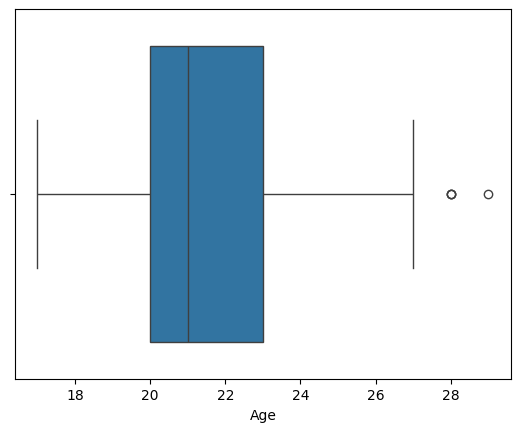

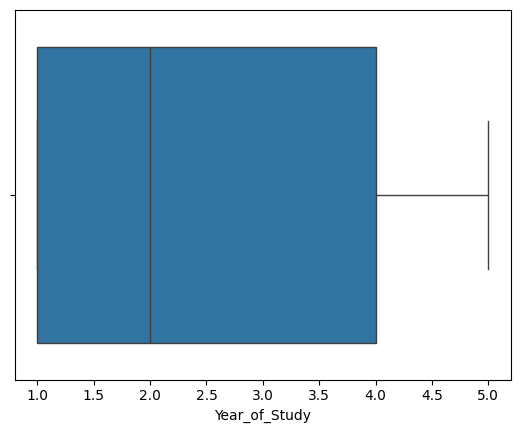

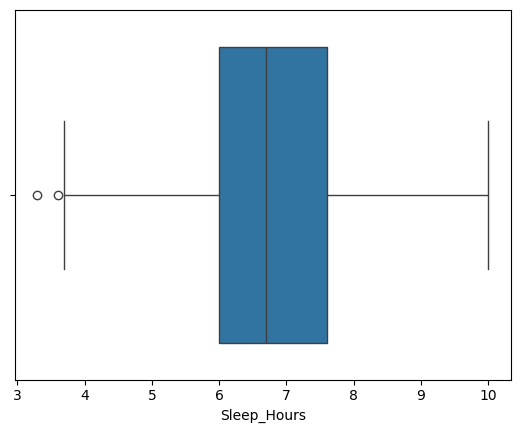

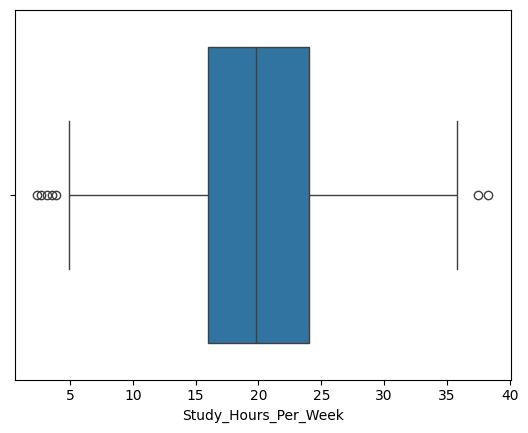

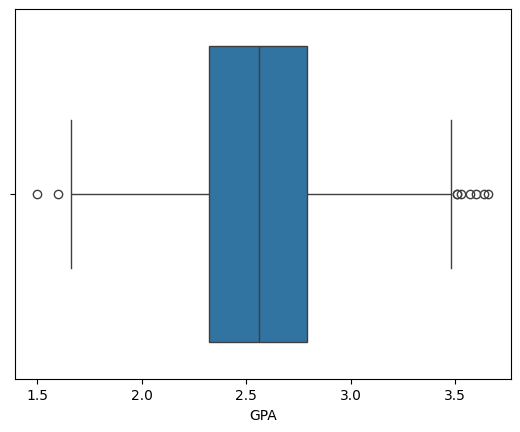

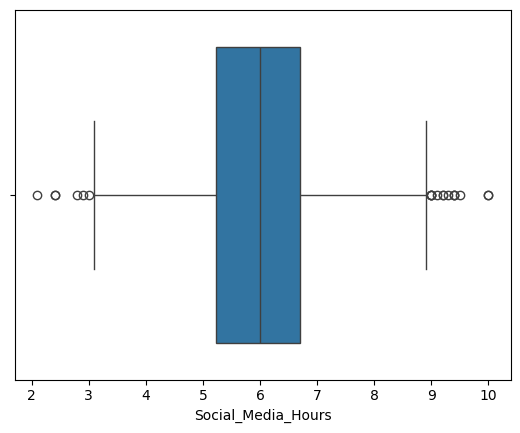

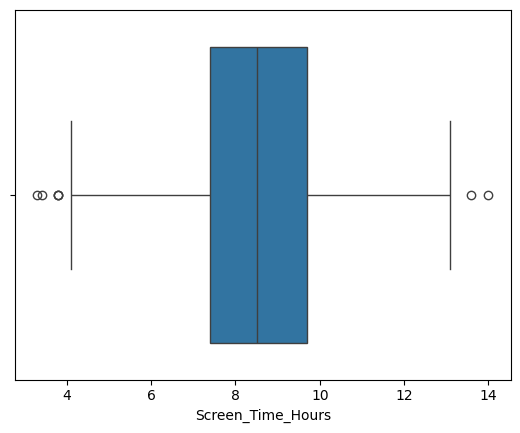

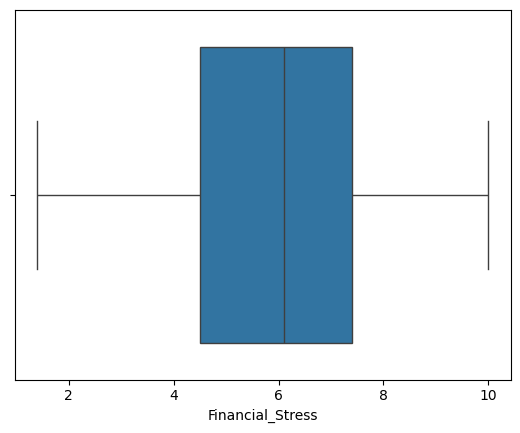

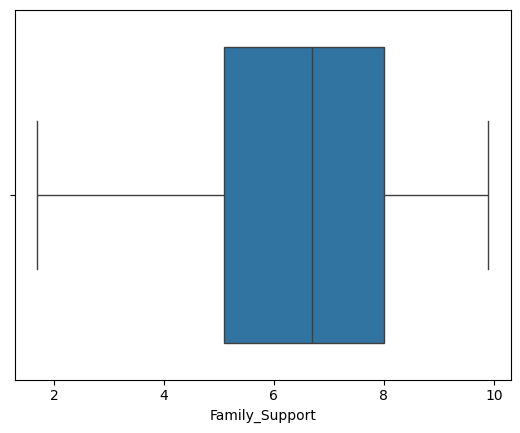

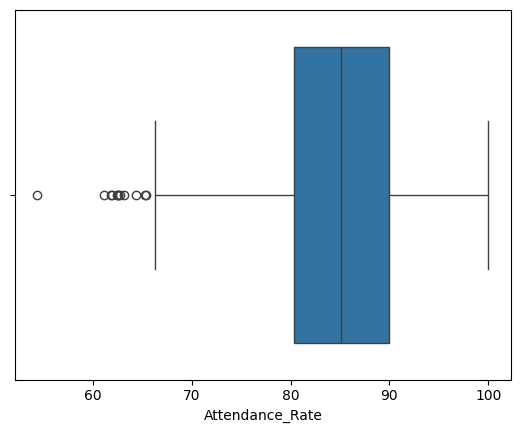

In [53]:
for col in numerical_columns:
    sns.boxplot(x=df[col])
    plt.show()

In [54]:
for col in numerical_columns:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(col, n)

Age 4
Year_of_Study 0
Sleep_Hours 2
Study_Hours_Per_Week 7
GPA 9
Social_Media_Hours 20
Screen_Time_Hours 7
Financial_Stress 0
Family_Support 0
Attendance_Rate 12


## 1-3 Produire des statistiques descriptives

In [55]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


## 1-4 Étudier la distribution de la variable cible et l'éventuel déséquilibre des classes

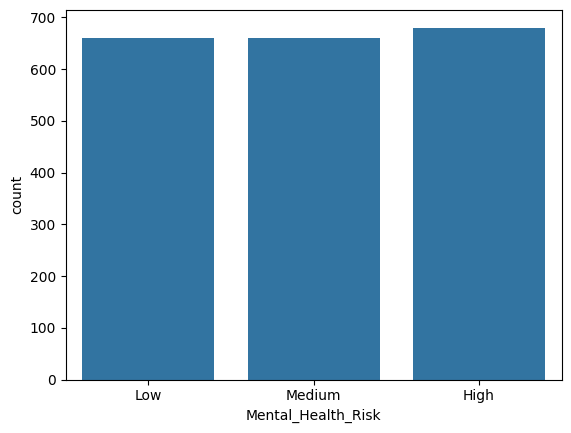

In [56]:
sns.countplot(data=df, x='Mental_Health_Risk', order=['Low', 'Medium', 'High'])
plt.show()

In [57]:
print(df['Mental_Health_Risk'].value_counts(normalize=True).round(1))

Mental_Health_Risk
High      0.3
Medium    0.3
Low       0.3
Name: proportion, dtype: float64


## 1-5 Analyser les relations entre les variables explicatives et la cible

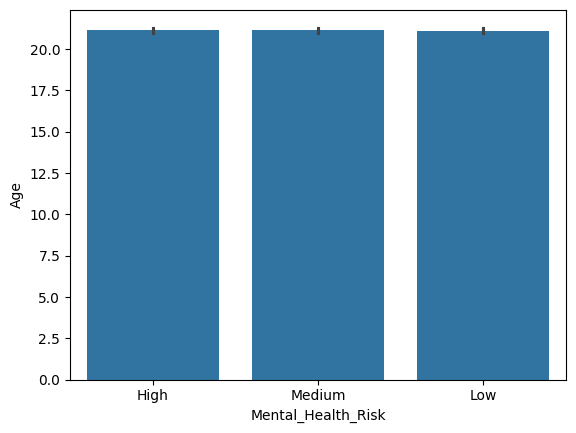

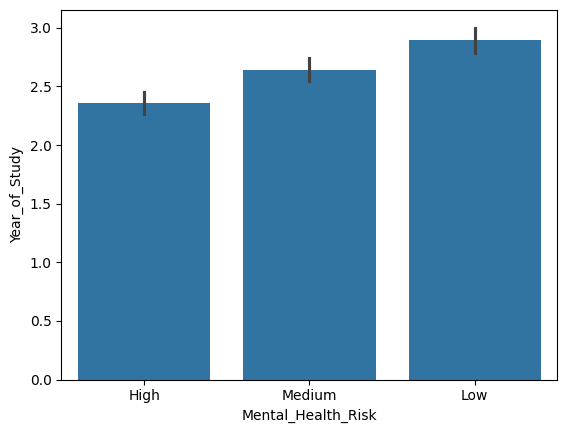

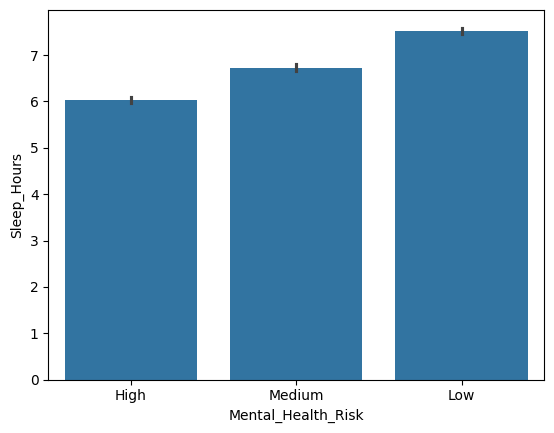

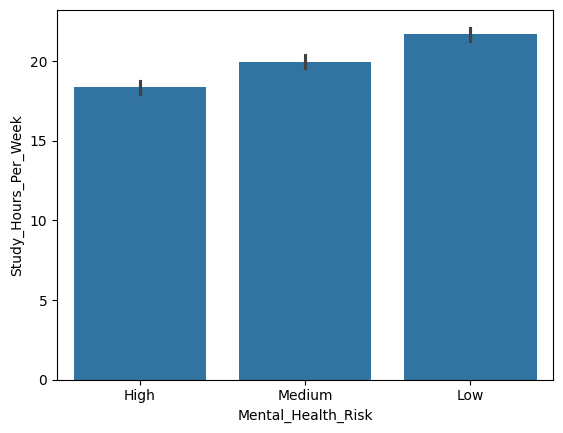

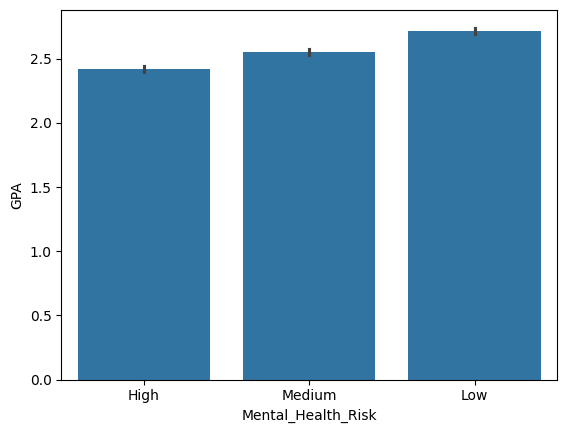

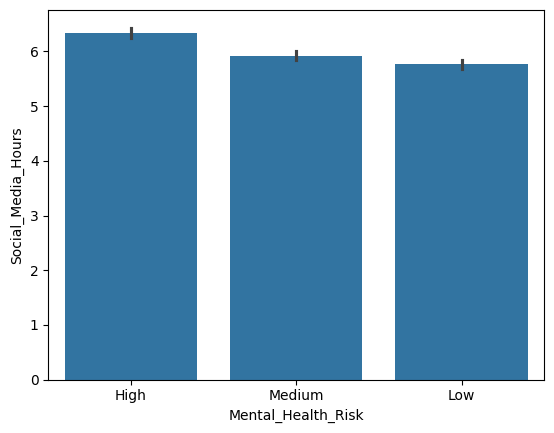

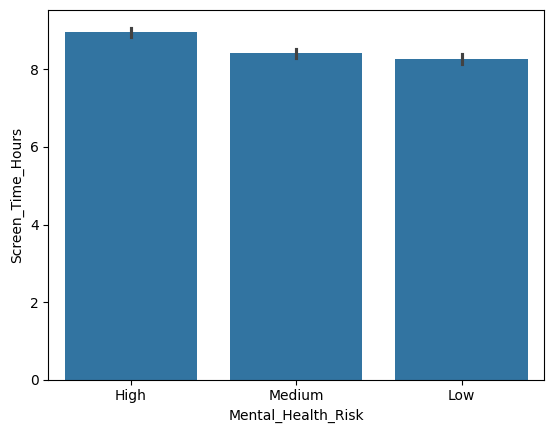

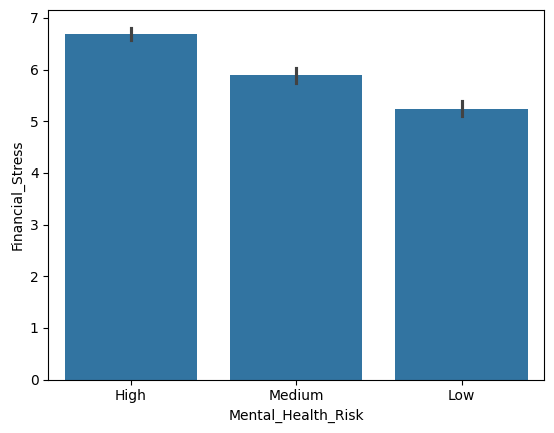

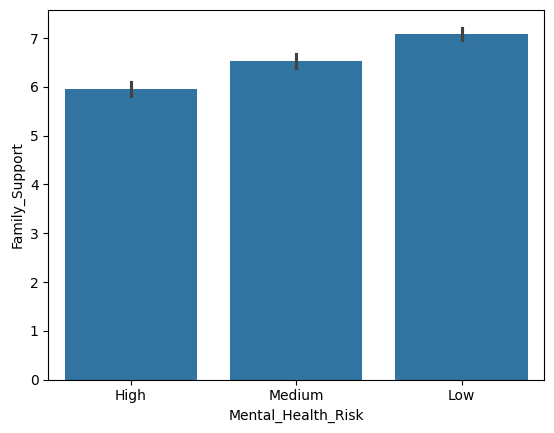

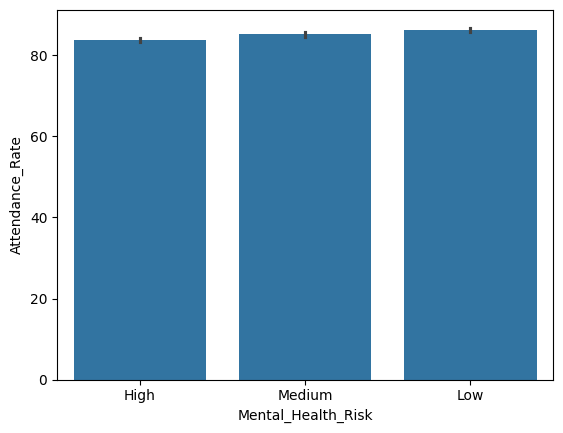

In [58]:
for col in numerical_columns:
    sns.barplot(data = df , x = "Mental_Health_Risk" , y = col)
    plt.show()

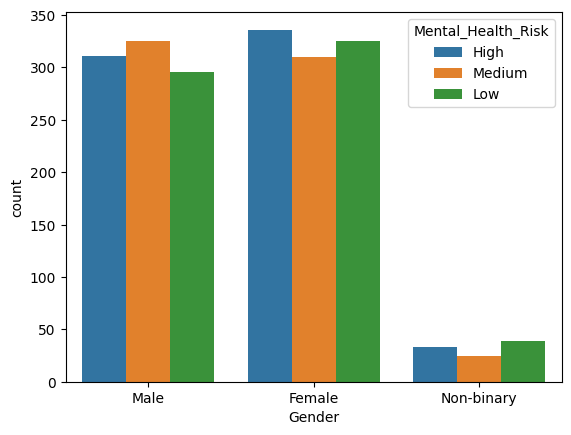

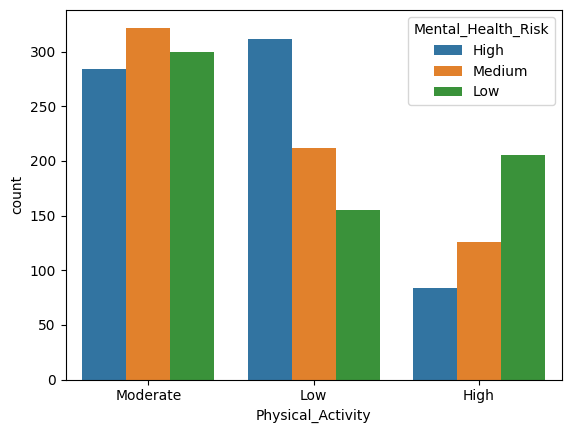

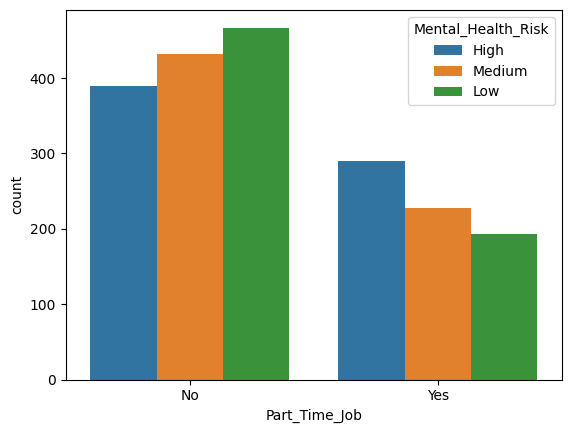

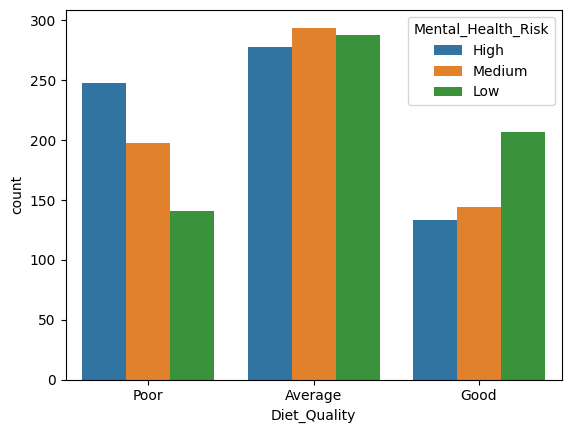

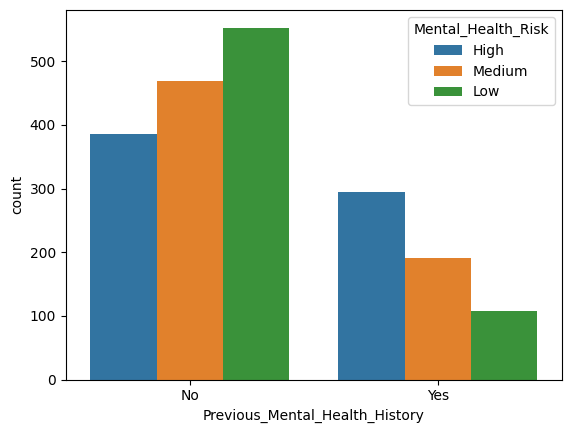

In [59]:
for col in categorical_columns:
    if col != 'Mental_Health_Risk':
        sns.countplot(x=df[col], hue=df['Mental_Health_Risk'])
        plt.show()

## 1-6 Examiner les corrélations entre les variables

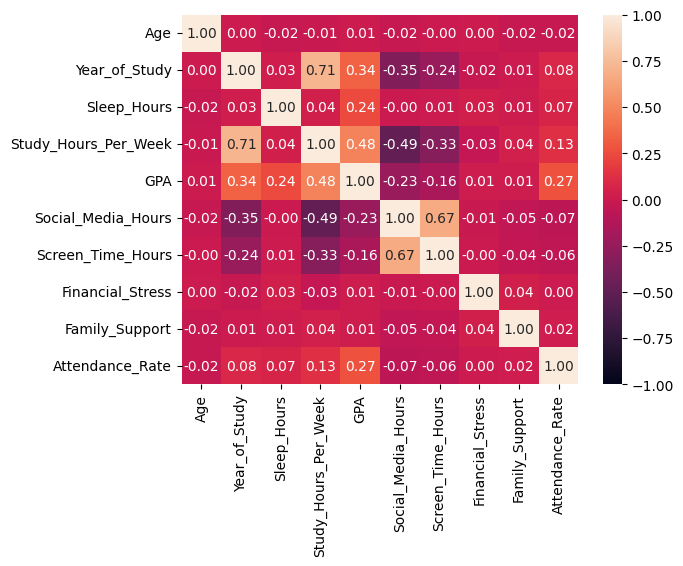

In [60]:
corr = df[numerical_columns].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1)
plt.show()

## 1-7 Identifier les variables les plus fortement liées au niveau de risque

In [61]:
risk = df['Mental_Health_Risk'].map({'Low': 0, 'Medium': 1, 'High': 2})
corr_risk = df[numerical_columns].assign(risk=risk).corr(method='spearman')['risk'].drop('risk')
print(corr_risk.sort_values(key=abs, ascending=False))

Sleep_Hours            -0.541219
GPA                    -0.344298
Financial_Stress        0.311370
Family_Support         -0.250298
Study_Hours_Per_Week   -0.240049
Social_Media_Hours      0.198289
Screen_Time_Hours       0.173464
Year_of_Study          -0.165839
Attendance_Rate        -0.141808
Age                     0.005131
Name: risk, dtype: float64


In [62]:
for col in categorical_columns.drop('Mental_Health_Risk'):
    print(pd.crosstab(df[col], df['Mental_Health_Risk'], normalize='index').mul(100).round(1), '\n')

Mental_Health_Risk  High   Low  Medium
Gender                                
Female              34.6  33.5    31.9
Male                33.4  31.8    34.9
Non-binary          34.0  40.2    25.8 

Mental_Health_Risk  High   Low  Medium
Physical_Activity                     
High                20.2  49.4    30.4
Low                 45.9  22.8    31.2
Moderate            31.3  33.1    35.5 

Mental_Health_Risk  High   Low  Medium
Part_Time_Job                         
No                  30.3  36.2    33.5
Yes                 40.8  27.1    32.1 

Mental_Health_Risk  High   Low  Medium
Diet_Quality                          
Average             32.3  33.5    34.2
Good                27.5  42.8    29.8
Poor                42.2  24.0    33.7 

Mental_Health_Risk              High   Low  Medium
Previous_Mental_Health_History                    
No                              27.4  39.3    33.3
Yes                             49.7  18.1    32.3 



In [63]:
print(df[numerical_columns].skew().round(2))

Age                     0.20
Year_of_Study           0.31
Sleep_Hours             0.05
Study_Hours_Per_Week    0.04
GPA                     0.09
Social_Media_Hours      0.09
Screen_Time_Hours      -0.04
Financial_Stress       -0.17
Family_Support         -0.30
Attendance_Rate        -0.12
dtype: float64
